# Introduction to Artificial Intelligence (AI)

### What is AI?
Artificial Intelligence (AI) is a branch of computer science dedicated to creating systems capable of performing tasks that typically require human intelligence. These tasks include learning, reasoning, problem-solving, perception, and understanding natural language.

### The Goals of AI
* **To Create Expert Systems:** Systems that exhibit intelligent behavior, learn, demonstrate, explain, and advise its users.
* **To Implement Human Intelligence in Machines:** Creating systems that understand, think, learn, and behave like humans.
* **Problem Solving & Reasoning:** Enabling machines to process complex information and make logical decisions.
* **Adaptability:** Allowing models to generalize and adapt to new, unseen data or environments.

---

### Subsets of AI

AI is a broad umbrella term that encompasses several specialized domains:

```
   Artificial Intelligence (AI)
        │
        └──► Machine Learning (ML)
                 │
                 └──► Deep Learning (DL)
```

#### Machine Learning (ML)
Machine Learning is a subset of AI that focuses on building systems that learn from data to improve performance over time without being explicitly programmed. It includes:
* **Supervised Learning:** Training models on labeled data (e.g., Credit Card Fraud Detection).
* **Unsupervised Learning:** Finding hidden patterns in unlabeled data (e.g., customer segmentation).
* **Reinforcement Learning:** Training agents to make a sequence of decisions by rewarding desired behaviors.

#### Deep Learning (DL)
Deep Learning is a specialized subfield of ML based on Artificial Neural Networks (ANNs) with multiple layers (hence "deep"). Inspired by the structure of the human brain, DL algorithms are exceptionally good at processing unstructured data like raw images, audio, and large-scale text.

#### Computer Vision (CV)
Computer Vision enables computers and systems to derive meaningful information from digital images, videos, and other visual inputs. Real-world applications include:
* Autonomous vehicles (e.g., Tesla Autopilot)
* Facial recognition security systems
* Medical image analysis (e.g., tumor detection)

#### Natural Language Processing (NLP)
Natural Language Processing focuses on the interaction between computers and human language. It allows machines to read, decipher, understand, and generate human languages. Examples include:
* Large Language Models (LLMs) like Gemini and GPT
* Machine Translation (e.g., Google Translate)
* Sentiment Analysis & Chatbots

---

### Applications of AI
* **Healthcare:** Disease diagnosis, personalized medicine, and drug discovery.
* **Finance:** Fraud detection, algorithmic trading, and automated credit scoring.
* **E-commerce:** Recommendation engines (e.g., Amazon, Netflix) and dynamic pricing.
* **Automotive:** Self-driving technology and smart driver-assist systems.

### 1. Credit Card Fraud Detection

**Problem:** Credit card fraud detection is a classic highly-imbalanced binary classification problem where the goal is to identify fraudulent transactions from legitimate ones.

**Method:**
- We generate a balanced synthetic dataset representing credit card transactions.
- Split the dataset into 80% training and 20% testing sets using stratified splitting to preserve class proportions.
- Standardize the features based only on the training set to prevent data leakage.
- Train and compare four different machine learning classification algorithms: **Logistic Regression**, **Decision Trees**, **Random Forests**, and **Gradient Boosting**.
- Evaluate performance using metrics suited for classification tasks: Accuracy, Precision, Recall, and F-Score.

In [ ]:
import time
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Create a balanced toy dataset
X, y = make_classification(
    n_samples=200, n_features=5, n_informative=4,
    n_redundant=0, weights=[0.5, 0.5], random_state=42
)
X = pd.DataFrame(X, columns=[f"V{i}" for i in range(1, 6)])

# 2. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3. Scale features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Define the models
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 5. Train and evaluate each model
results = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start

    start = time.time()
    y_pred = model.predict(X_test_scaled)
    test_time = time.time() - start

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "Train Time": train_time,
        "Test Time": test_time
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score  Train Time  \
0  Logistic Regression     0.675     0.6522    0.75    0.6977      0.0832   
1        Decision Tree     0.725     0.6957    0.80    0.7442      0.0090   
2        Random Forest     0.775     0.7391    0.85    0.7907      0.6959   
3    Gradient Boosting     0.825     0.7826    0.90    0.8372      0.7061   

   Test Time  
0     0.0005  
1     0.0025  
2     0.0203  
3     0.0031  


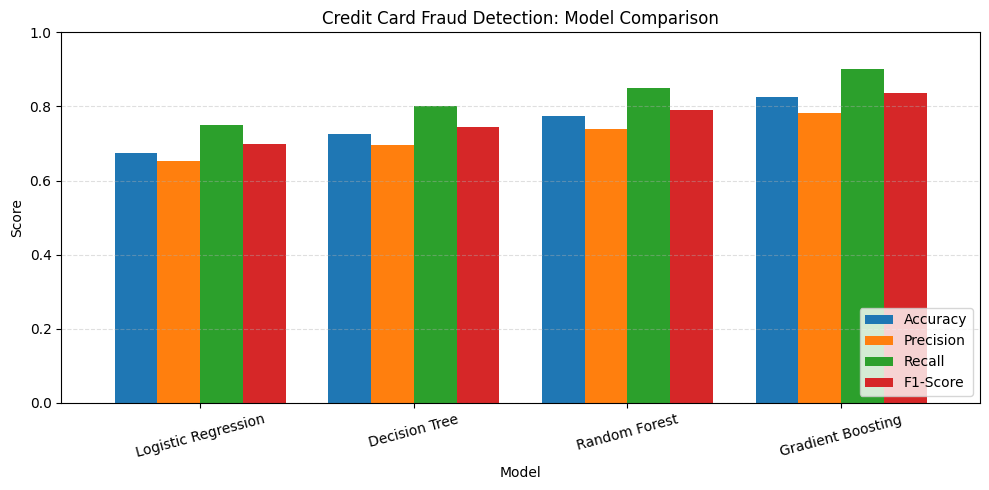

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1),
    rot=15, width=0.8
)

plt.title("Credit Card Fraud Detection: Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 2. Predicting House Prices


**Problem:** Predicting house prices is a regression problem where the target variable (`SalePrice`) is continuous. The task is to predict this continuous output based on both numerical (e.g., area, quality) and categorical (e.g., zoning, style) attributes.

**Method:**
- Generate a synthetic housing dataset containing heterogeneous numerical and categorical columns.
- Partition the data into training and testing sets.
- Implement a robust data preprocessing pipeline using `ColumnTransformer` to scale numerical features and one-hot encode categorical features.
- Train and compare three regressors: **Linear Regression**, **Random Forest Regressor**, and a **Support Vector Regressor (SVR)**.
- Evaluate predictions using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Generate a synthetic housing dataset
rng = np.random.default_rng(42)
n = 500

df = pd.DataFrame({
    "Id": np.arange(1, n + 1),
    "MSSubClass": rng.choice([20, 30, 50, 60, 70], n),
    "MSZoning": rng.choice(["RL", "RM", "FV", "RH"], n),
    "LotArea": rng.integers(2000, 15000, n),
    "LotConfig": rng.choice(["Inside", "Corner", "CulDSac"], n),
    "BldgType": rng.choice(["1Fam", "Duplex", "Townhouse"], n),
    "OverallCond": rng.integers(3, 10, n),
    "YearBuilt": rng.integers(1950, 2024, n),
    "YearRemodAdd": rng.integers(1950, 2025, n),
    "Exterior1st": rng.choice(["VinylSd", "Wd Sdng", "MetalSd"], n),
    "BsmtFinSF2": rng.integers(0, 500, n),
    "TotalBsmtSF": rng.integers(300, 2000, n)
})

# Create a synthetic target with feature effects and random noise
df["SalePrice"] = (
    40000
    + 25 * df["LotArea"]
    + 45 * df["TotalBsmtSF"]
    + 2500 * df["OverallCond"]
    + 500 * (df["YearBuilt"] - 1950)
    + df["MSZoning"].map({"RL": 20000, "RM": 0, "FV": 30000, "RH": -5000})
    + rng.normal(0, 20000, n)
).clip(lower=30000)

# 2. Separate features and target
X = df.drop(columns=["Id", "SalePrice"])
y = df["SalePrice"]

numeric = X.select_dtypes(include="number").columns
categorical = X.select_dtypes(exclude="number").columns

# 3. Split before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
])

# 4. Define and train the models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": SVR(kernel="rbf")
}

results = []
predictions = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R²": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
print(results_df.round(2))

               Model       MAE      RMSE    R²
0  Linear Regression  16402.34  20153.15  0.95
1      Random Forest  20046.80  25372.02  0.92
2                SVR  76528.66  90664.23  0.00


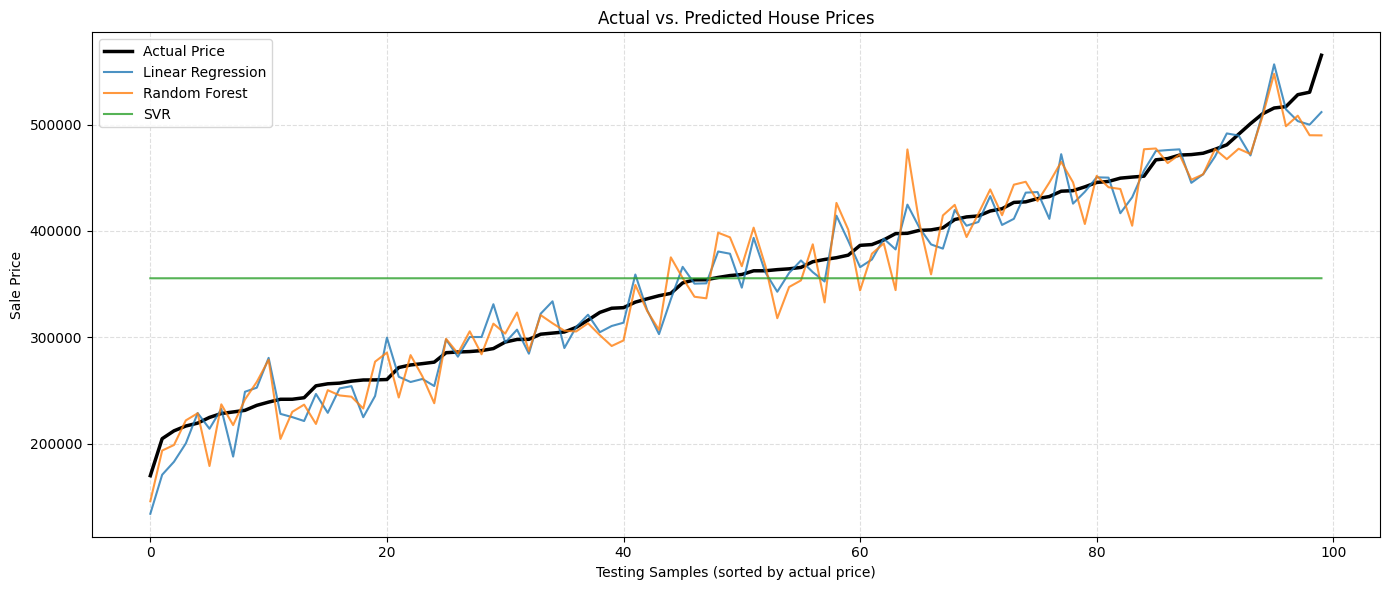

In [ ]:
# Sort test samples by actual price for easier visual comparison
order = np.argsort(y_test.to_numpy())
actual = y_test.to_numpy()[order]

plt.figure(figsize=(14, 6))

plt.plot(actual, label="Actual Price", linewidth=2.5, color="black")
for name, y_pred in predictions.items():
    plt.plot(y_pred[order], label=name, alpha=0.8)

plt.title("Actual vs. Predicted House Prices")
plt.xlabel("Testing Samples (sorted by actual price)")
plt.ylabel("Sale Price")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 3. Movie Review Sentiment Analysis


**Problem:** Sentiment analysis on the IMDB dataset is a binary text-classification task where the model learns to identify whether a movie review is positive or negative.

**Method:**
- Load the IMDB movie review dataset, keeping the top 12,000 most frequent words.
- Convert variable-length review sequences into fixed-length multi-hot vector encodings using Keras `CategoryEncoding`.
- Design a Deep Learning model with a sequence of fully connected (`Dense`) layers with ReLU activations, ending with a single unit sigmoid layer to output class probabilities.
- Train the Neural Network using Binary Cross-Entropy loss and the Adam optimizer.
- Plot loss and accuracy curves to evaluate model convergence and generalization capability on the test partition.


In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

import numpy as np

# Set the vocabulary size
vocab_size = 12000

# Load the dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training samples: 25000
Testing samples: 25000


In [ ]:
# Convert each review into a multi-hot vector
encoder = tf.keras.layers.CategoryEncoding(
    num_tokens=vocab_size,
    output_mode="multi_hot"
)

X_train = encoder(
    tf.ragged.constant(X_train, dtype=tf.int32)
).numpy()

X_test = encoder(
    tf.ragged.constant(X_test, dtype=tf.int32)
).numpy()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (25000, 12000)
Testing shape: (25000, 12000)


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(vocab_size,)),

    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       192,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 192,161 (750.63 KB)

 Trainable params: 192,161 (750.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8577 - loss: 0.3415 - val_accuracy: 0.8956 - val_loss: 0.2737
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9377 - loss: 0.1686 - val_accuracy: 0.8822 - val_loss: 0.3007
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9630 - loss: 0.1040 - val_accuracy: 0.8818 - val_loss: 0.3784
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9794 - loss: 0.0619 - val_accuracy: 0.8768 - val_loss: 0.4516
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9901 - loss: 0.0325 - val_accuracy: 0.8768 - val_loss: 0.5360


In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.5977342128753662
Test Accuracy: 0.8568400144577026


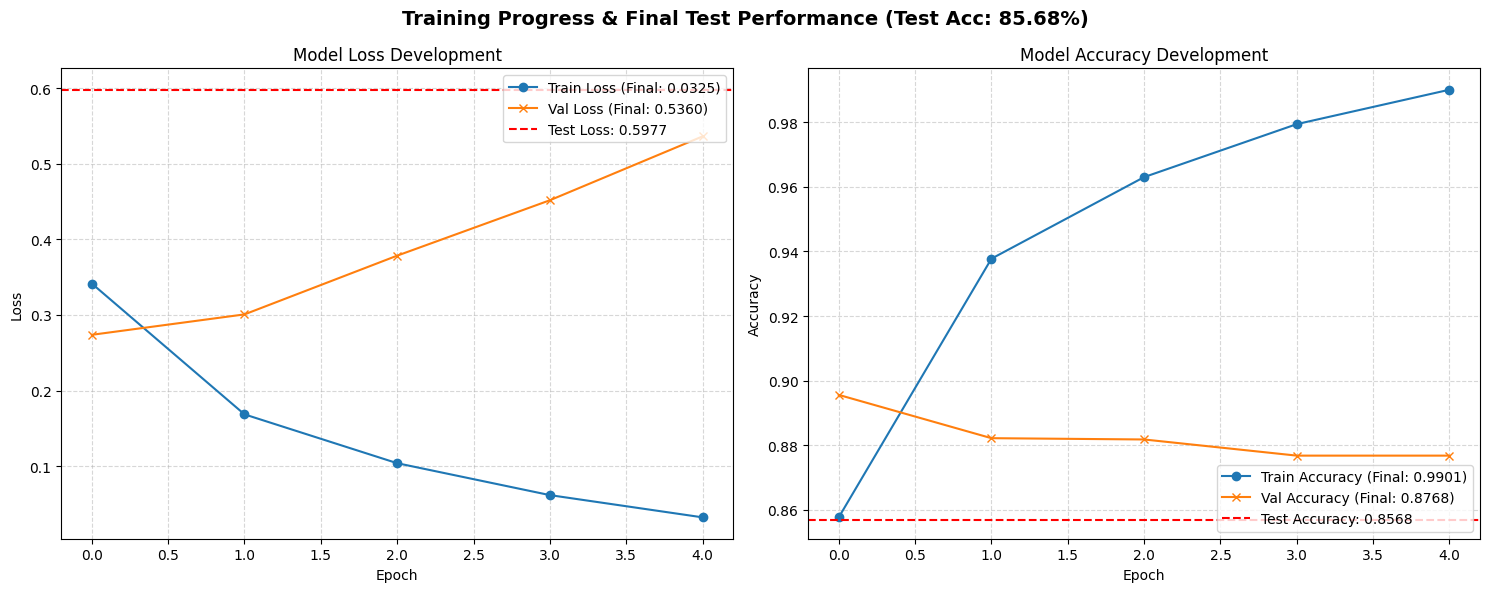

In [ ]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot Loss
ax1.plot(history.history['loss'], label=f"Train Loss (Final: {history.history['loss'][-1]:.4f})", marker='o')
ax1.plot(history.history['val_loss'], label=f"Val Loss (Final: {history.history['val_loss'][-1]:.4f})", marker='x')
ax1.axhline(test_loss, color='r', linestyle='--', label=f"Test Loss: {test_loss:.4f}")
ax1.set_title("Model Loss Development")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend(loc="upper right")
ax1.grid(True, linestyle="--", alpha=0.5)

# Plot Accuracy
ax2.plot(history.history['accuracy'], label=f"Train Accuracy (Final: {history.history['accuracy'][-1]:.4f})", marker='o')
ax2.plot(history.history['val_accuracy'], label=f"Val Accuracy (Final: {history.history['val_accuracy'][-1]:.4f})", marker='x')
ax2.axhline(test_accuracy, color='r', linestyle='--', label=f"Test Accuracy: {test_accuracy:.4f}")
ax2.set_title("Model Accuracy Development")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend(loc="lower right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.suptitle(f"Training Progress & Final Test Performance (Test Acc: {test_accuracy*100:.2f}%)", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Select five testing samples
X_sample = X_test[:5]
y_sample = y_test[:5]

# Predict sentiment probabilities
predictions = model.predict(X_sample, verbose=0)

for i in range(5):
    probability = predictions[i][0]
    predicted_label = 1 if probability >= 0.5 else 0

    predicted_sentiment = (
        "Positive" if predicted_label == 1 else "Negative"
    )

    actual_sentiment = (
        "Positive" if y_sample[i] == 1 else "Negative"
    )

    print(f"Review {i + 1}")
    print(f"Predicted sentiment: {predicted_sentiment}")
    print(f"Positive probability: {probability:.4f}")
    print(f"Actual sentiment: {actual_sentiment}")
    print("-" * 30)

Review 1
Predicted sentiment: Negative
Positive probability: 0.0043
Actual sentiment: Negative
------------------------------
Review 2
Predicted sentiment: Positive
Positive probability: 1.0000
Actual sentiment: Positive
------------------------------
Review 3
Predicted sentiment: Negative
Positive probability: 0.0233
Actual sentiment: Positive
------------------------------
Review 4
Predicted sentiment: Positive
Positive probability: 0.9283
Actual sentiment: Negative
------------------------------
Review 5
Predicted sentiment: Positive
Positive probability: 0.9917
Actual sentiment: Positive
------------------------------


### 4. Image Compression


**Problem:** High-resolution digital images require significant storage space. Image compression reduces this overhead by minimizing the total number of unique colors used to represent the image.

**Method:**
- We utilize **K-Means Clustering** as a vector quantization technique.
- An input image is converted into an RGB pixel coordinate array.
- We sub-sample a representative batch of pixels to efficiently train the K-Means algorithm and find $K$ cluster centroids (optimal color representatives).
- Each pixel in the original image is mapped to its nearest centroid, replacing millions of colors with just $K$ colors.
- Finally, we reconstruct, display, and export the compressed image file.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.cluster import KMeans
from google.colab import files

In [ ]:
def compress_image(image, k):
    # Convert image into a NumPy array
    image_array = np.array(image.convert("RGB"))

    # Get image dimensions
    height, width, channels = image_array.shape

    # Reshape the image into a list of RGB pixels
    pixels = image_array.reshape(-1, 3)

    # Randomly sample pixels to train K-Means
    rng = np.random.default_rng(42)
    sample_size = min(10000, len(pixels))
    sample_indices = rng.choice(
        len(pixels), size=sample_size, replace=False
    )
    sample_pixels = pixels[sample_indices]

    # Train the K-Means model
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(sample_pixels)

    # Assign every pixel to its closest cluster centroid
    labels = model.predict(pixels)

    # Replace each pixel with its cluster's representative color
    compressed_pixels = model.cluster_centers_[labels]

    # Reconstruct the image
    compressed_array = np.clip(
        compressed_pixels.reshape(height, width, 3),
        0, 255
    ).astype(np.uint8)

    return Image.fromarray(compressed_array)

Saving image.jpg to image (4).jpg


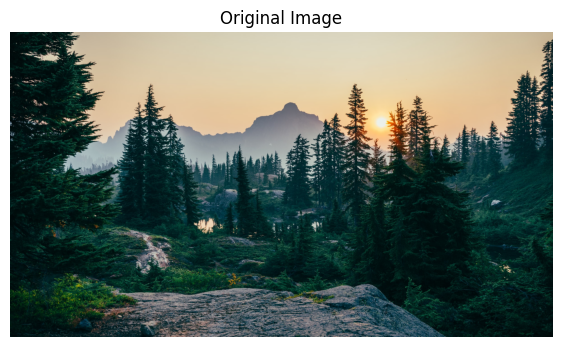

Enter the number of colors (K): 16


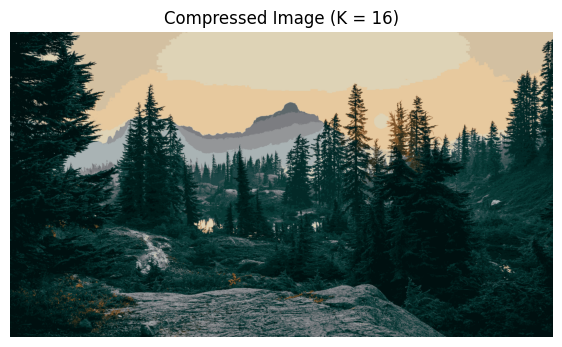

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Upload an image
uploaded = files.upload()

# Get the uploaded filename
filename = next(iter(uploaded))

# Open the original image
original_image = Image.open(filename).convert("RGB")

# Display the original image
plt.figure(figsize=(7, 5))
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Choose the number of representative colors
k = int(input("Enter the number of colors (K): "))

# Validate K
if not 1 <= k <= 256:
    raise ValueError("K must be between 1 and 256.")

# Compress the image
compressed_image = compress_image(original_image, k)

# Display the compressed image
plt.figure(figsize=(7, 5))
plt.imshow(compressed_image)
plt.title(f"Compressed Image (K = {k})")
plt.axis("off")
plt.show()

# Save the compressed image as PNG
output_filename = "compressed_image.png"
compressed_image.save(output_filename, format="PNG")

# Download the result
files.download(output_filename)